# 355. Design Twitter
**Difficulty:** 🟡 Medium · **Topic:** Heap · **Pattern:** [K Way Merge](README.md) · **LeetCode:** https://leetcode.com/problems/design-twitter/

## 💡 Concepts

**Core concept(s):** **hash maps** for who-posted-what and who-follows-whom, plus a **k-way merge with a min-heap** to build the news feed.

**Why it applies here:**
- Each user's own tweets are stored in the order they were posted, so every user's tweet list is already **sorted by time**.
- A news feed is "the 10 most recent tweets across me and everyone I follow": that is merging `k` sorted lists (one per user) and stopping after 10.
- A heap holding the newest unread tweet of each of the `k` users always surfaces the next most recent tweet in `O(log k)`.

**Key intuition:**
- Read each list from its **end** (newest first), the way you would merge `k` sorted lists from their heads.
- Pop the newest tweet, then push the next-older tweet *from the same user*.
- Stop after 10 pops: the feed never touches the rest of the tweets.

---

**What is a Hash Map?**
- A hash map (Python `dict`) stores key → value pairs.
- It hashes each key to pick a slot in an array, so it jumps straight to the value instead of scanning.
- Insert, lookup and delete are **O(1) on average**.
- In Python: `dict`, and `collections.defaultdict(list)` / `defaultdict(set)` when a missing key should start as an empty list or set.
- Why it matters here: `tweets[user]` and `following[user]` are found in `O(1)`, so post, follow and unfollow are all `O(1)`.

**What is a Set?**
- A set stores unique items with no order.
- Membership test, add and remove (`discard`) are **O(1) on average**.
- In Python: `set`. `discard(x)` removes `x` and does nothing if `x` is absent, unlike `remove`, which raises `KeyError`.
- Why it matters here: following the same person twice must not duplicate them, and unfollowing someone you never followed must not crash.

**What is a Heap (Priority Queue)?**
- A heap is a tree packed into an array where every parent is no bigger than its children (a **min-heap**), so the smallest item is always at index `0`.
- Push and pop are **O(log n)**; peeking at the smallest is **O(1)**; `heapify` turns a list into a heap in **O(n)**.
- In Python: `heapq` on a plain list. It is a min-heap only: to pop the **largest** time first, store `-time`.
- Tuples compare item by item, so `(-time, tweetId, userId, index)` is ordered by `-time` first. Times are unique here, so the later items never decide the order.

**What is a K-Way Merge?**
- You have `k` sorted lists and want one sorted output.
- Put the front item of each list into a min-heap. Pop the smallest, output it, and push the next item from the same list.
- Each output item costs `O(log k)`; you can stop early once you have as many items as you need.

**What is a Class (object-oriented design)?**
- A class bundles data (attributes such as `self.tweets`) with the methods that change it.
- LeetCode "design" problems call the constructor once, then call methods in a given order; each method must see the state left by the previous calls.
- In Python: `class Twitter:` with `__init__` for the state. A subclass (`class Twitter(TwitterBrute)`) reuses every method and overrides only the ones it redefines.

---

**Prerequisite knowledge:**
- [Merge k Sorted Lists](merge_k_sorted_lists.ipynb): the same heap merge on linked lists.

## 📝 Problem

Design a simplified Twitter with four operations:
- `postTweet(userId, tweetId)`: the user posts a new tweet with a unique id.
- `getNewsFeed(userId)`: return the ids of the **10 most recent** tweets posted by the user **or by anyone the user follows**, most recent first.
- `follow(followerId, followeeId)`: the follower starts following the followee.
- `unfollow(followerId, followeeId)`: the follower stops following the followee.

A user always sees their own tweets. Following yourself, or unfollowing yourself, changes nothing.

**Example 1** (LeetCode)
```
ops  = ["Twitter", "postTweet", "getNewsFeed", "follow", "postTweet", "getNewsFeed", "unfollow", "getNewsFeed"]
args = [[],        [1, 5],      [1],           [1, 2],   [2, 6],      [1],           [1, 2],     [1]]
out  = [None,      None,        [5],           None,     None,        [6, 5],        None,       [5]]
```
- User 1 posts tweet 5 → feed `[5]`.
- User 1 follows user 2, user 2 posts tweet 6 → feed `[6, 5]` (6 is newer).
- User 1 unfollows user 2 → feed back to `[5]`.

**Example 2** — the demo used on the interactive page
```
post(1, 11) post(2, 21) post(3, 31) post(2, 22) post(1, 12) post(3, 32) post(2, 23)
follow(1, 2) follow(1, 3)
getNewsFeed(1)  ->  [23, 32, 12, 22, 31, 21, 11]
```

**Constraints:** `1 <= userId, followerId, followeeId <= 500`, `0 <= tweetId <= 10^4`, all tweet ids are unique, at most `3 * 10^4` calls in total.

> Two approaches: gather every relevant tweet and sort (`O(T log T)` per feed), then the k-way merge with a heap that stops after 10 tweets (`O(k + 10 log k)` per feed). There is no meaningful third approach, so the notebook has two.

In [1]:
import heapq
import random
from collections import defaultdict
from typing import List

def run_ops(cls, ops, args):
    """Replay a LeetCode-style operation list on a fresh instance of `cls`; return every call's result."""
    obj, out = None, []
    for op, a in zip(ops, args):
        if op == "Twitter":
            obj = cls(); out.append(None)       # the constructor returns nothing
        else:
            out.append(getattr(obj, op)(*a))    # e.g. obj.postTweet(1, 5)
    return out

### Approach 1 — Brute Force: gather every tweet, sort, take 10

**Idea:**
1. Keep `tweets[user]` = list of `(time, tweetId)` in posting order, and `following[user]` = set of followees. A global counter `time` stamps each tweet.
2. `postTweet`, `follow`, `unfollow` are plain dict/set updates; `follow` ignores a user following themselves.
3. `getNewsFeed(u)`: copy the user's own tweets, add every followee's tweets, sort the whole pool newest first, return the first 10 ids.

**Time complexity:**
- `postTweet`, `follow`, `unfollow`: `O(1)`.
- `getNewsFeed`: `O(T log T)`, where `T` = number of tweets posted by the user and their followees. Every one of them is copied and sorted, although only 10 are returned.

**Space complexity:** `O(T)` extra per feed call for the pool (storage of all tweets and follows aside).

In [2]:
class TwitterBrute:
    def __init__(self):
        self.time = 0                              # global clock: a larger time = a more recent tweet
        self.tweets = defaultdict(list)            # user -> [(time, tweetId), ...] in posting order
        self.following = defaultdict(set)          # user -> set of followees (never contains the user)

    def postTweet(self, userId: int, tweetId: int) -> None:
        self.tweets[userId].append((self.time, tweetId))
        self.time += 1

    def getNewsFeed(self, userId: int) -> List[int]:
        pool = list(self.tweets[userId])           # own tweets are always in the feed
        for f in self.following[userId]:
            pool.extend(self.tweets[f])            # every tweet of every followee: T tweets in total
        pool.sort(reverse=True)                    # newest first: O(T log T), even though we need only 10
        return [tid for _, tid in pool[:10]]

    def follow(self, followerId: int, followeeId: int) -> None:
        if followerId != followeeId:               # following yourself is a no-op (you already see your tweets)
            self.following[followerId].add(followeeId)   # a set: following twice adds nothing

    def unfollow(self, followerId: int, followeeId: int) -> None:
        self.following[followerId].discard(followeeId)   # discard: no error if not followed (or self)

### Approach 2 — K-Way Merge with a heap (optimal · pattern template)

**Idea:** the [K Way Merge](README.md) template. Storage and the three update methods are the same as Approach 1; only `getNewsFeed` changes.
1. The sources are the user and every followee: `k` lists, each already sorted by time (oldest → newest).
2. Seed a heap with each source's **newest** tweet: `(-time, tweetId, userId, index)`. `-time` makes Python's min-heap pop the most recent tweet first; `index` says where we are in that user's list.
3. Pop the top → it is the most recent remaining tweet overall; add its id to the feed.
4. Push the **next-older** tweet of the same user (`index - 1`), if there is one.
5. Stop when the feed has 10 ids or the heap is empty.

**Time complexity:**
- `postTweet`, `follow`, `unfollow`: `O(1)`.
- `getNewsFeed`: `O(k + 10 log k)`, where `k` = followees + 1. Seeding and `heapify` cost `O(k)`; at most 10 pops and 10 pushes cost `O(log k)` each. The total number of tweets `T` does not appear.

**Space complexity:** `O(k)` for the heap (storage aside).

In [3]:
class Twitter(TwitterBrute):
    """Same storage and post/follow/unfollow as TwitterBrute; only the feed is a k-way merge."""

    def getNewsFeed(self, userId: int) -> List[int]:
        heap = []
        for uid in self.following[userId] | {userId}:     # the k sources: followees + the user themself
            tl = self.tweets[uid]
            if tl:
                t, tid = tl[-1]                            # newest tweet of this source = end of its list
                heap.append((-t, tid, uid, len(tl) - 1))   # -t: heapq is a min-heap, we want the max time
        heapq.heapify(heap)                                # O(k)
        feed = []
        while heap and len(feed) < 10:                     # stop after 10: the rest is never read
            _, tid, uid, i = heapq.heappop(heap)           # most recent remaining tweet across all sources
            feed.append(tid)
            if i > 0:                                      # same user has an older tweet: it joins the race
                t, nid = self.tweets[uid][i - 1]
                heapq.heappush(heap, (-t, nid, uid, i - 1))
        return feed

In [4]:
# Correctness check
cases = [
    # LeetCode example 1
    (["Twitter", "postTweet", "getNewsFeed", "follow", "postTweet", "getNewsFeed", "unfollow", "getNewsFeed"],
     [[], [1, 5], [1], [1, 2], [2, 6], [1], [1, 2], [1]],
     [None, None, [5], None, None, [6, 5], None, [5]]),
    # Example 2 (the interactive page's demo): three users, interleaved posts
    (["Twitter"] + ["postTweet"] * 7 + ["follow", "follow", "getNewsFeed"],
     [[], [1, 11], [2, 21], [3, 31], [2, 22], [1, 12], [3, 32], [2, 23], [1, 2], [1, 3], [1]],
     [None] * 10 + [[23, 32, 12, 22, 31, 21, 11]]),
    # More than 10 tweets: only the 10 most recent come back
    (["Twitter"] + ["postTweet"] * 12 + ["getNewsFeed"],
     [[]] + [[1, t] for t in range(12)] + [[1]],
     [None] * 13 + [[11, 10, 9, 8, 7, 6, 5, 4, 3, 2]]),
    # Follow / unfollow self are no-ops: own tweets stay visible, nothing is duplicated
    (["Twitter", "postTweet", "follow", "getNewsFeed", "unfollow", "getNewsFeed"],
     [[], [1, 7], [1, 1], [1], [1, 1], [1]],
     [None, None, None, [7], None, [7]]),
    # Following twice does not duplicate; unfollowing a stranger does not crash; empty feed
    (["Twitter", "getNewsFeed", "postTweet", "follow", "follow", "getNewsFeed", "unfollow", "unfollow", "getNewsFeed"],
     [[], [1], [2, 9], [1, 2], [1, 2], [1], [1, 3], [1, 2], [1]],
     [None, [], None, None, None, [9], None, None, []]),
]
for ops, args, exp in cases:
    for cls in (TwitterBrute, Twitter):
        got = run_ops(cls, ops, args)
        assert got == exp, f"{cls.__name__}: {got} != {exp}"
print(f"{len(cases)} scripted cases: both designs match the expected outputs")

# Randomised cross-check: replay the same random operations on both designs
rng = random.Random(355)
for _ in range(200):
    b, h, next_id = TwitterBrute(), Twitter(), 0
    for _ in range(rng.randint(1, 80)):
        op, u, v = rng.random(), rng.randint(1, 6), rng.randint(1, 6)
        if op < 0.45:
            b.postTweet(u, next_id); h.postTweet(u, next_id); next_id += 1
        elif op < 0.65:
            b.follow(u, v); h.follow(u, v)
        elif op < 0.75:
            b.unfollow(u, v); h.unfollow(u, v)
        else:
            assert b.getNewsFeed(u) == h.getNewsFeed(u)
print("200 random operation scripts: brute and heap feeds agree")

print("\nAll tests passed")

5 scripted cases: both designs match the expected outputs
200 random operation scripts: brute and heap feeds agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time one `getNewsFeed` call on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(1)` / `O(log n)` | ≈ **1×** |
| `O(n)` / `O(n log n)` | ≈ **2×** (slightly more for `n log n`) |
| `O(n²)` | ≈ **4×** |

**Worst-case input:** user 0 follows a fixed `k = 50` users, and `n` tweets are spread round-robin over them, so every followee has about `n / 50` tweets.
- The brute force copies and sorts all `T = n` tweets on every call → its time should roughly **double** with `n`.
- The heap version reads `k + 10` entries whatever `n` is → its time should stay **flat (≈1×)**.

Both designs share the same storage (`Twitter` subclasses `TwitterBrute`), so one prebuilt instance is timed with each version of `getNewsFeed`; building the instance is not timed.


gather+sort O(T log T)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
    10000 |       0.45 |           n/a
    20000 |       1.27 |         2.83x
    40000 |       2.18 |         1.71x
    80000 |       5.87 |         2.70x

heap merge  O(k + 10 log k)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
    10000 |       0.01 |           n/a
    20000 |       0.01 |         1.09x
    40000 |       0.01 |         0.97x
    80000 |       0.01 |         1.07x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


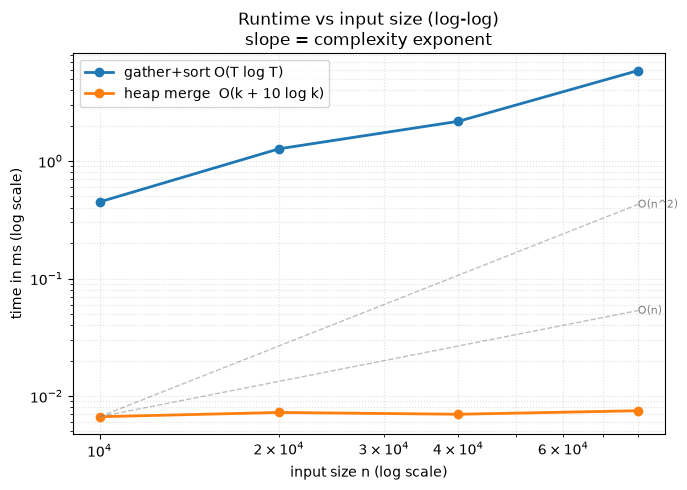

{'gather+sort O(T log T)': [0.44824997894465923,
  1.2694579781964421,
  2.175999921746552,
  5.871666944585741],
 'heap merge  O(k + 10 log k)': [0.00666698906570673,
  0.0072499969974160194,
  0.0069999368861317635,
  0.007500057108700275]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n, k=50):
    tw = Twitter()
    for f in range(1, k + 1):
        tw.follow(0, f)
    for t in range(n):
        tw.postTweet(1 + t % k, t)        # round-robin: every followee keeps posting, n tweets in total
    return (tw,)

solutions = {
    "gather+sort O(T log T)": lambda tw: TwitterBrute.getNewsFeed(tw, 0),   # brute feed on the same storage
    "heap merge  O(k + 10 log k)": lambda tw: Twitter.getNewsFeed(tw, 0),
}
sizes = [10000, 20000, 40000, 80000]

benchmark(solutions, make_worst_case, sizes, repeats=5, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [K Way Merge](README.md) — every user's tweet list is sorted by time, so the feed is a k-way merge of the user's and followees' lists, read newest-first with a heap of `(-time, ...)` and stopped after 10 pops.
- **Design = choose the storage that makes the hot query cheap:** append-only per-user lists keep each source sorted for free (the clock only goes up), so no sorting is ever needed.
- **Max-heap in Python:** `heapq` is a min-heap; negate the key (`-time`) to pop the largest first.
- **Carry a cursor in the heap entry:** `(key, payload, source, index)` tells you which list to advance after a pop, exactly like `(val, list_index, node)` in Merge k Sorted Lists.
- **Early stop:** a k-way merge produces items in order, so "top 10 most recent" costs `O(k + 10 log k)` instead of sorting everything.
- **Signal:** "most recent N across several feeds", "merge k sorted streams", "news feed / timeline", "design" + "top N by time".
- **Related problems:** Merge k Sorted Lists, Kth Smallest Element in a Sorted Matrix, Find K Pairs with Smallest Sums, Smallest Range Covering Elements from K Lists.
- **Common pitfalls:**
  1. Forgetting the user's **own** tweets in the feed.
  2. Following yourself and then seeing your own tweets twice (or `unfollow` raising `KeyError` with `set.remove`).
  3. Pushing all `T` tweets into the heap — that is the brute force with extra steps (`O(T log T)`).
  4. Using a min-heap on `time` without negating it, which returns the **oldest** tweets.